# Elliptic PDEs



In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats('pdf', 'png')
plt.rcParams['figure.dpi']= 300
plt.rcParams['savefig.dpi'] = 300

\begin{equation}
\frac{\partial^2 u}{\partial x^2} + \frac{\partial^2 u}{\partial y^2} = \nabla^2 u = 0 \;,
\end{equation}

\begin{equation}
\frac{\partial u}{\partial t} = \alpha \left( \frac{\partial^2 u}{\partial x^2} + \frac{\partial^2 u}{\partial y^2} \right) \;,
\end{equation}

\begin{equation}
\nabla^2 u = f(x,y) \;,
\end{equation}

\begin{align}
\frac{\partial^2 u}{\partial x^2} &\approx \frac{u_{i-1,j} - 2u_{i,j} + u_{i+1,j}}{\Delta x^2} \\
\frac{\partial^2 u}{\partial y^2} &\approx \frac{u_{i,j-1} - 2u_{i,j} + u_{i,j+1}}{\Delta y^2}
\end{align}

\begin{equation}
\frac{u_{i-1,j} - 2u_{i,j} + u_{i+1,j}}{\Delta x^2} + \frac{u_{i,j-1} - 2u_{i,j} + u_{i,j+1}}{\Delta y^2} = 0 \;.
\end{equation}

\begin{equation}
u_{i+1,j} + u_{i,j+1} + u_{i-1,j} + u_{i,j-1} - 4 u_{i,j} = 0 \;.
\end{equation}

\begin{equation}
\frac{\partial^2 u}{\partial x^2} + \frac{\partial^2 u}{\partial y^2} = \nabla^2 u = 0 \;,
\end{equation}

\begin{equation}
u_{i+1,j} + u_{i,j+1} + u_{i-1,j} + u_{i,j-1} - 4 u_{i,j} = 0 \;.
\end{equation}

\begin{align}
u_{0,0} &= 100 \\
u_{1,0} &= 100 \\
u_{2,0} &= 100 \\
u_{0,1} &= 100 \\
\text{for } u_{1,1}: \quad u_{2,1} + u_{1,2} + u_{0,1} + u_{1,0} - 4u_{1,1} &= 0 \\
u_{2,1} &= 100 \\
u_{0,2} &= 100 \\
u_{1,2} &= 0 \\
u_{2,2} &= 100
\end{align}

\begin{align}
\begin{bmatrix} 
1 & 0 & 0 & 0 &  0 & 0 & 0 & 0 & 0 \\
0 & 1 & 0 & 0 &  0 & 0 & 0 & 0 & 0 \\
0 & 0 & 1 & 0 &  0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 1 &  0 & 0 & 0 & 0 & 0 \\
0 & 1 & 0 & 1 & -4 & 1 & 0 & 1 & 0 \\
0 & 0 & 0 & 0 &  0 & 1 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 &  0 & 0 & 1 & 0 & 0 \\
0 & 0 & 0 & 0 &  0 & 0 & 0 & 1 & 0 \\
0 & 0 & 0 & 0 &  0 & 0 & 0 & 0 & 1 \\\end{bmatrix}
\begin{bmatrix} u_{0,0} \\ u_{1,0} \\ u_{2,0} \\ u_{0,1} \\ u_{1,1} \\ u_{2,1} \\ u_{0,2} \\ u_{1,2} \\ u_{2,2} \end{bmatrix} &= 
\begin{bmatrix} 100 \\ 100 \\ 100 \\ 
100 \\ 0 \\ 100 \\
100 \\ 0 \\ 100 \end{bmatrix} \\
\text{or} \quad A \mathbf{u} &= \mathbf{b}
\end{align}

In [3]:
A = np.array([
    [1, 0, 0, 0, 0, 0, 0, 0, 0],
    [0, 1, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 1, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 1, 0, 0, 0, 0, 0],
    [0, 1, 0, 1,-4, 1, 0, 1, 0],
    [0, 0, 0, 0, 0, 1, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 1, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 1, 0],
    [0, 0, 0, 0, 0, 0, 0, 0, 1]
    ])

b = np.array([100, 100, 100, 100, 0, 100, 100, 0, 100])
u = np.linalg.solve(A, b)
print(u)

[100. 100. 100. 100.  75. 100. 100.   0. 100.]


In [4]:
A = np.eye(9)
A[4, 1] = 1
A[4, 3] = 1
A[4, 4] = -4
A[4, 5] = 1
A[4, 7] = 1
u2 = np.linalg.solve(A, b)
assert np.all(u == u2)

\begin{equation}
u_{i,j} = \frac{u_{i+1,j} + u_{i,j+1} + u_{i-1,j} + u_{i,j-1}}{4} \;,
\end{equation}

In [5]:
b = np.array(range(10))
A = np.reshape(b, [2, 5])
print(A)

[[0 1 2 3 4]
 [5 6 7 8 9]]


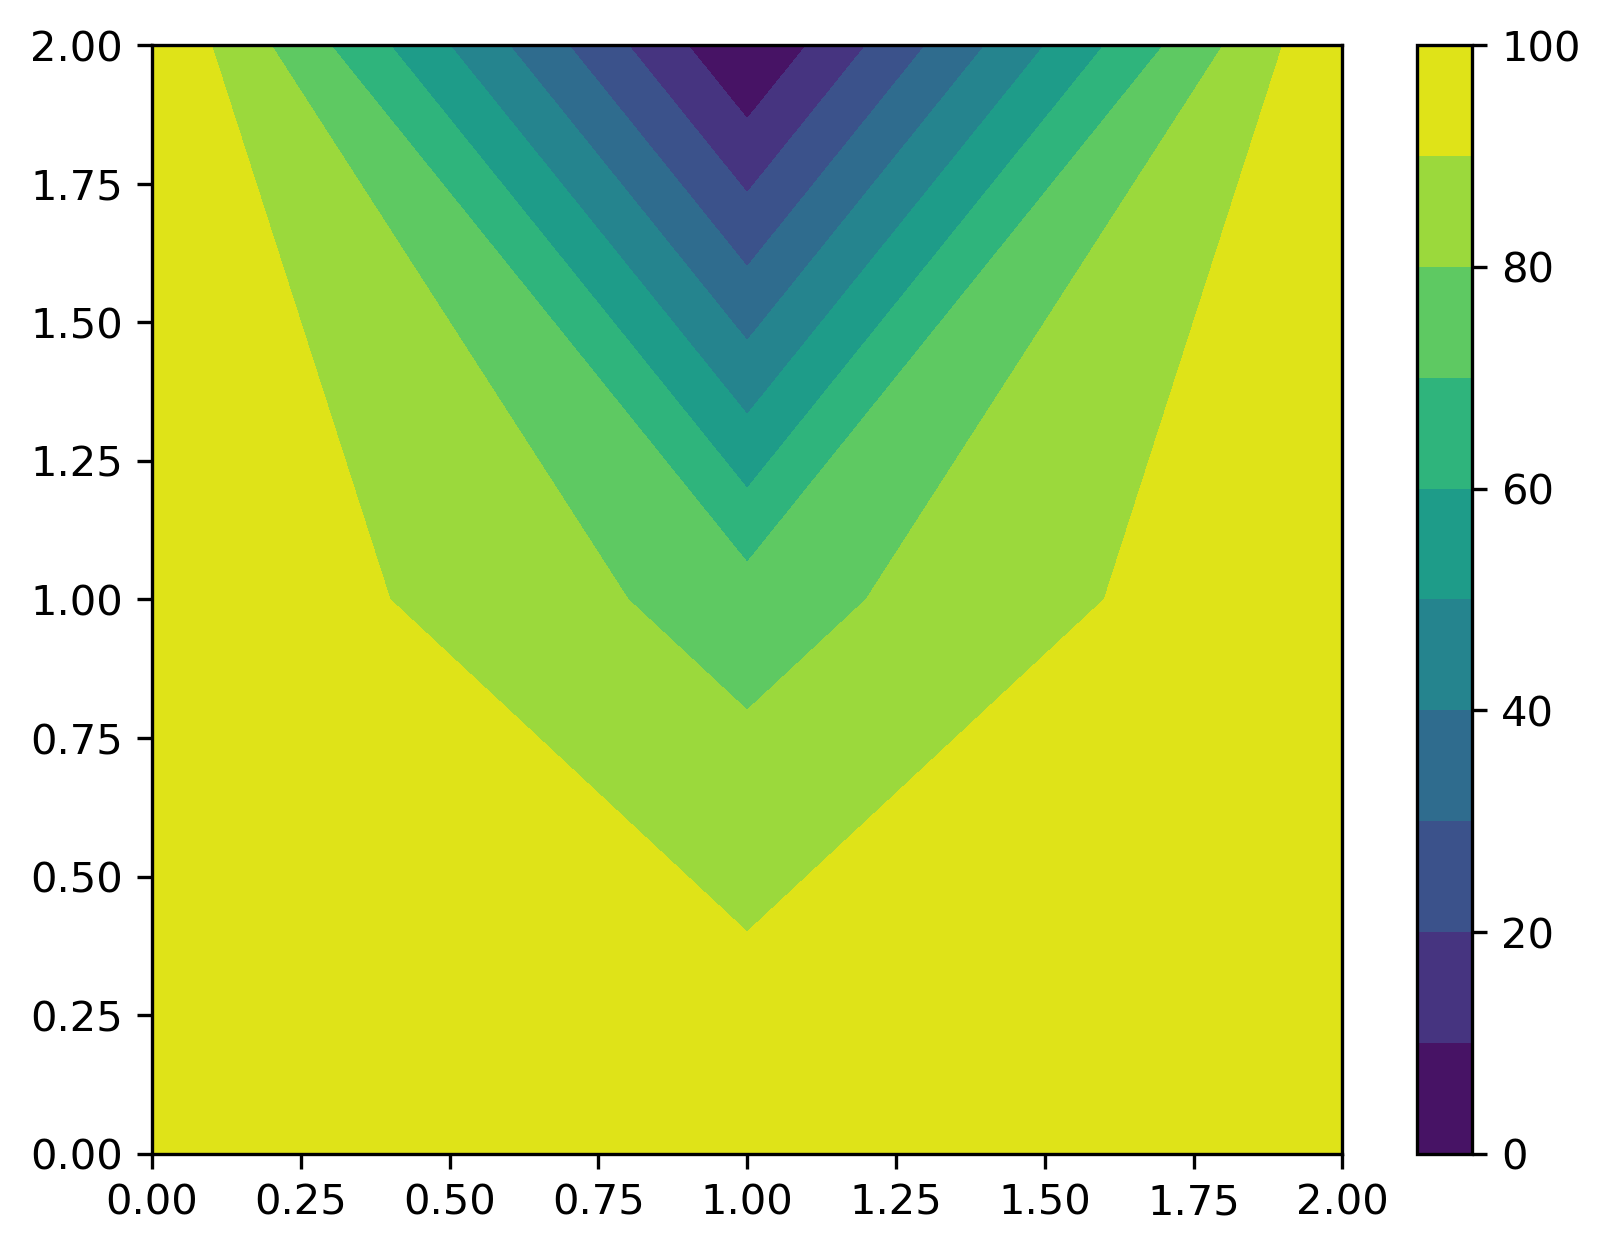

In [6]:
num_x = 3
num_y = 3
u_square = np.reshape(u, [num_y, num_x])

plt.contourf(u_square, levels=10)
plt.colorbar()
plt.show()

\begin{equation}
\begin{bmatrix} u_{0,0} \\ u_{1,0} \\ u_{2,0} \\ \vdots \\ u_{n-1,0} \\
u_{0,1} \\ u_{1,1} \\ u_{2,1} \\ \vdots \\ u_{n-1, 1} \\ u_{0,2} \\ \vdots \\
u_{0,m-1} \\ u_{1,m-1} \\ \vdots \\ u_{n-1,m-1}
\end{bmatrix}
\end{equation}

\begin{equation}
k_{i,j} = j n + i
\end{equation}

\begin{equation}
k_{1,1} = (1) 3 + 1 = 4
\end{equation}

\begin{align}
k_{i-1,j} &= j n + i - 1 \\
k_{i+1,j} &= j n + i + 1 \\
k_{i,j-1} &= (j-1)n + i \\
k_{i,j+1} &= (j+1) n + i
\end{align}

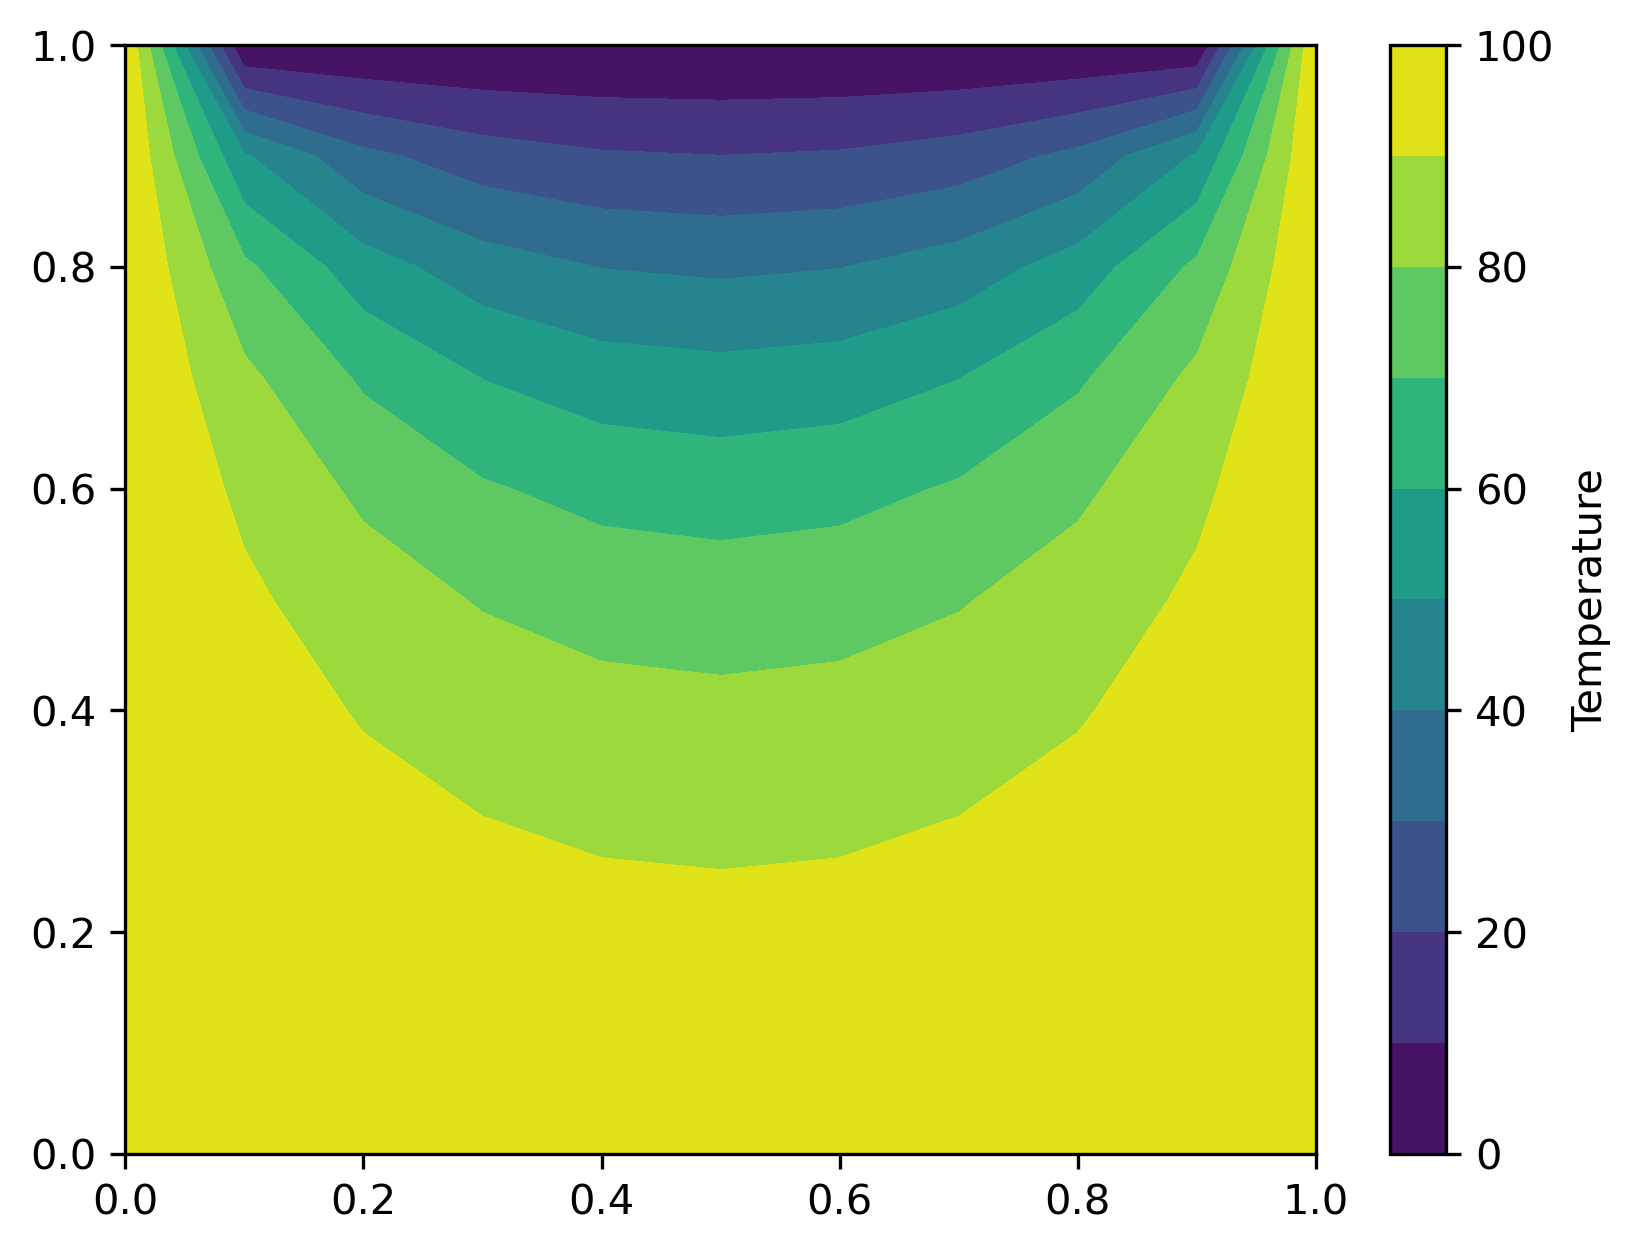

In [7]:
h = 0.1
length_x = 1.0
length_y = 1.0
x_vals = np.arange(0, length_x + 0.001, h)
y_vals = np.arange(0, length_y + 0.001, h)

A = np.zeros((len(x_vals)*len(y_vals), len(x_vals)*len(y_vals)))
b = np.zeros(len(x_vals)*len(y_vals))

u_left = 100
u_right = 100
u_bottom = 100
u_top = 0

for j, y in enumerate(y_vals):
    for i, x in enumerate(x_vals):
        
        kij = j*len(x_vals) + i
        kim1j = j*len(x_vals) + i - 1
        kip1j = j*len(x_vals) + i + 1
        kijm1 = (j-1)*len(x_vals) + i
        kijp1 = (j+1)*len(x_vals) + i
        if i == 0:
            # this is the left boundary
            A[kij, kij] = 1
            b[kij] = u_left
        elif i == len(x_vals) - 1:
            # right boundary
            A[kij, kij] = 1
            b[kij] = u_right
        elif j == 0:
            # bottom boundary
            A[kij, kij] = 1
            b[kij] = u_bottom
        elif j == len(y_vals) - 1:
            # top boundary
            A[kij, kij] = 1
            b[kij] = u_top
        else:

            A[kij, kim1j] = 1
            A[kij, kip1j] = 1
            A[kij, kijm1] = 1
            A[kij, kijp1] = 1
            A[kij, kij] = -4
u = np.linalg.solve(A, b)

u_square = np.reshape(u, (len(y_vals), len(x_vals)))
plt.contourf(x_vals, y_vals, u_square, levels=10)
plt.colorbar(label='Temperature')
plt.show()

\begin{equation}
\left. \frac{\partial u}{\partial y} \right|_{\text{boundary}} = 0
\end{equation}

\begin{align}
\frac{u_{2,3}}{\partial y} \approx \frac{u_{2,4} - u_{2,2}}{\Delta x} &= 0 \\
u_{2,4} &= u_{2,2}
\end{align}

\begin{align}
u_{1,3} + u_{3,3} + u_{2,4} + u_{2,2} - 4u_{2,3} &= 0 \\
u_{1,3} + u_{3,3} + u_{2,2} + u_{2,2} - 4u_{2,3} &= 0 \\
\rightarrow u_{1,3} + u_{3,3} + 2 u_{2,2} - 4u_{2,3} &= 0
\end{align}

\begin{equation}
u_{i+1,j} + u_{i-1,j} + 2 u_{i,j-1} - 4 u_{i,j} = 0 \;.
\end{equation}

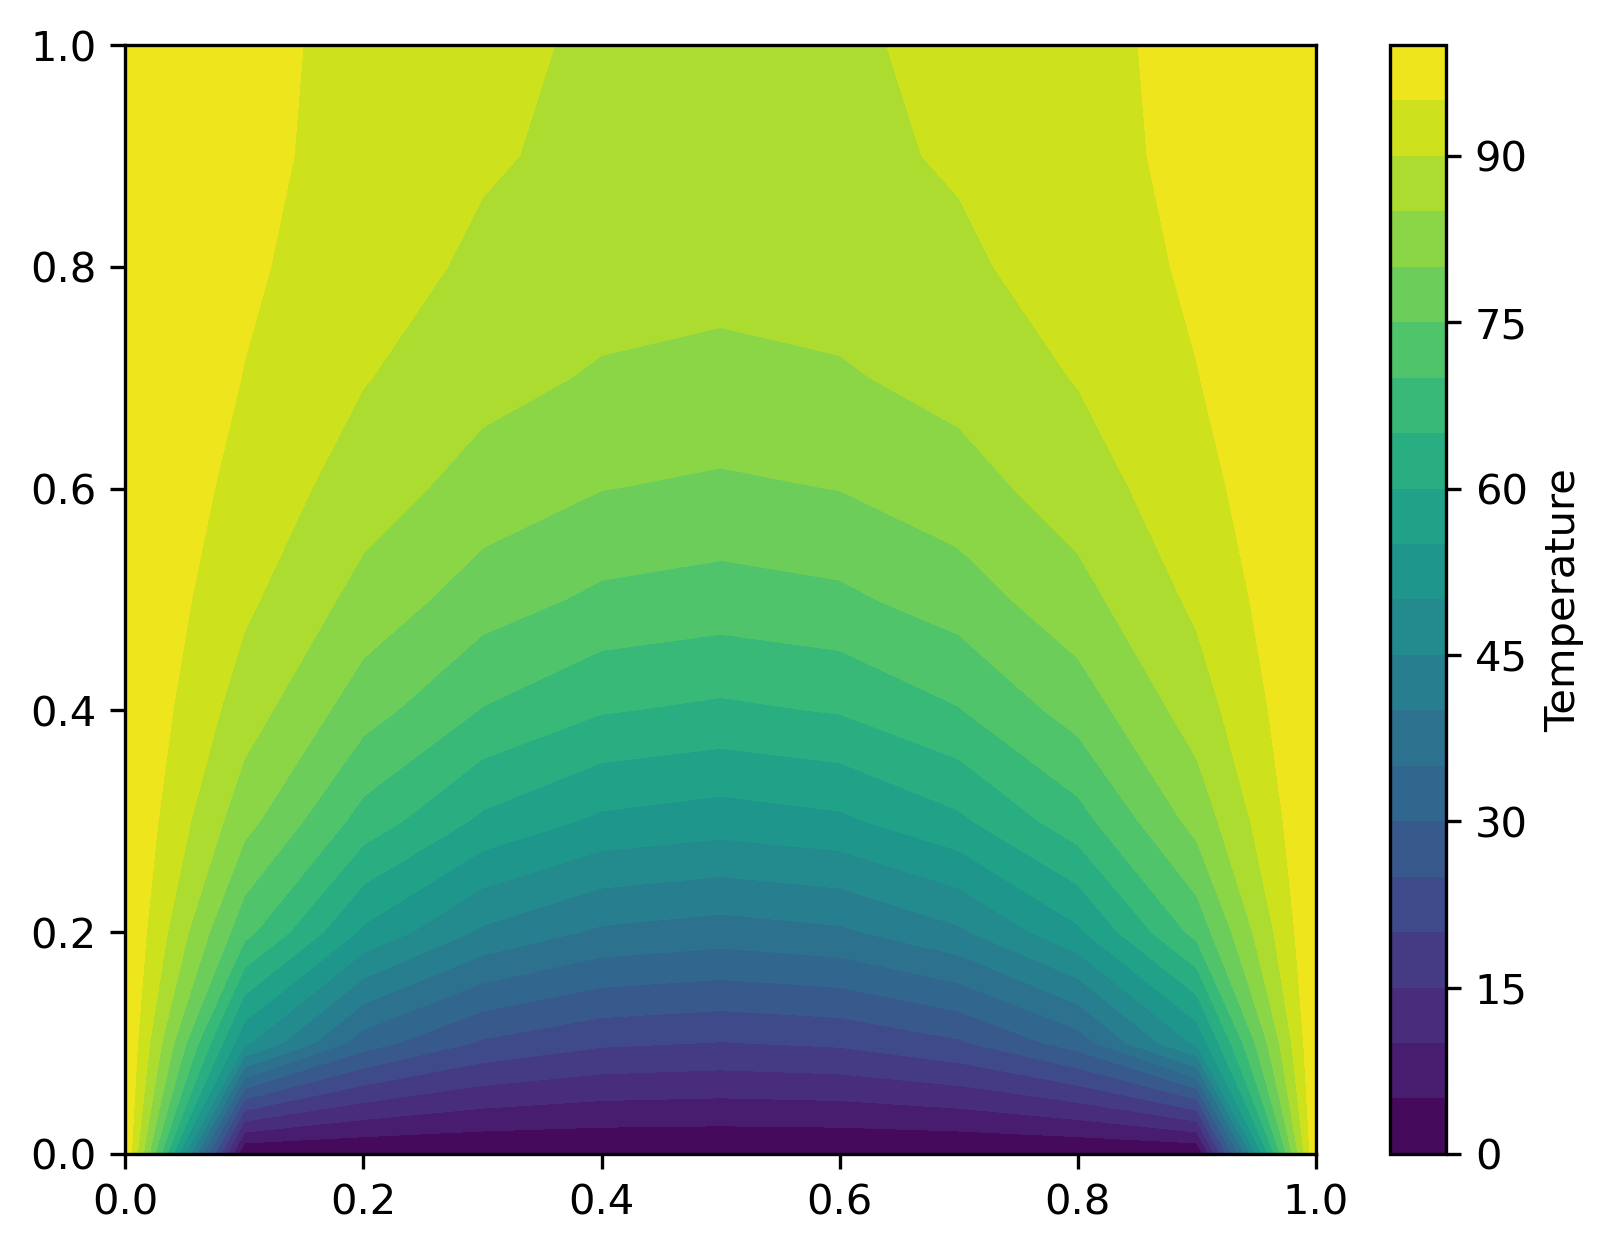

In [8]:
h = 0.1
length_x = 1.0
length_y = 1.0
x_vals = np.arange(0, length_x + 0.001, h)
y_vals = np.arange(0, length_y + 0.001, h)

A = np.zeros((len(x_vals)*len(y_vals), len(x_vals)*len(y_vals)))
b = np.zeros(len(x_vals)*len(y_vals))

u_left = 100
u_right = 100
u_bottom = 0

for j, y in enumerate(y_vals):
    for i, x in enumerate(x_vals):
        
        kij = j*len(x_vals) + i
        kim1j = j*len(x_vals) + i - 1
        kip1j = j*len(x_vals) + i + 1
        kijm1 = (j-1)*len(x_vals) + i
        kijp1 = (j+1)*len(x_vals) + i
        if i == 0:
            # this is the left boundary
            A[kij, kij] = 1
            b[kij] = u_left
        elif i == len(x_vals) - 1:
            # right boundary
            A[kij, kij] = 1
            b[kij] = u_right
        elif j == 0:
            # bottom boundary
            A[kij, kij] = 1
            b[kij] = u_bottom
        elif j == len(y_vals) - 1:
            # top boundary, using the ghost node + recursion formula            
            A[kij, kim1j] = 1
            A[kij, kip1j] = 1
            A[kij, kijm1] = 2
            A[kij, kij] = -4
        else:

            A[kij, kim1j] = 1
            A[kij, kip1j] = 1
            A[kij, kijm1] = 1
            A[kij, kijp1] = 1
            A[kij, kij] = -4
u = np.linalg.solve(A, b)

u_square = np.reshape(u, (len(y_vals), len(x_vals)))
plt.contourf(x_vals, y_vals, u_square, levels=20)
plt.colorbar(label='Temperature')
plt.show()

In [9]:
import time 

def heat_equation(h):
    '''Solves 2D steady heat equation problem given step size'''
    t0 = time.time()

    length_x = 1.0
    length_y = 1.0
    x_vals = np.arange(0, length_x + 0.001, h)
    y_vals = np.arange(0, length_y + 0.001, h)

    num_pts = len(x_vals)*len(y_vals)

    A = np.zeros((num_pts, num_pts))
    b = np.zeros(num_pts)

    u_left = 100
    u_right = 100
    u_bottom = 100
    u_top = 0

    for j, y in enumerate(y_vals):
        for i, x in enumerate(x_vals):
            
            kij = j*len(x_vals) + i
            kim1j = j*len(x_vals) + i - 1
            kip1j = j*len(x_vals) + i + 1
            kijm1 = (j-1)*len(x_vals) + i
            kijp1 = (j+1)*len(x_vals) + i
            if i == 0:
                # this is the left boundary
                A[kij, kij] = 1
                b[kij] = u_left
            elif i == len(x_vals) - 1:
                # right boundary
                A[kij, kij] = 1
                b[kij] = u_right
            elif j == 0:
                # bottom boundary
                A[kij, kij] = 1
                b[kij] = u_bottom
            elif j == len(y_vals) - 1:
                # top boundary
                A[kij, kij] = 1
                b[kij] = u_top
            else:

                A[kij, kim1j] = 1
                A[kij, kip1j] = 1
                A[kij, kijm1] = 1
                A[kij, kijp1] = 1
                A[kij, kij] = -4
    u = np.linalg.solve(A, b)
    u_square = np.reshape(u, (len(y_vals), len(x_vals)))

    return num_pts, (time.time() - t0)

In [10]:
step_sizes = [0.2, 0.1, 0.05]

num_pts = np.zeros(len(step_sizes))
times = np.zeros_like(num_pts)
for idx, step_size in enumerate(step_sizes):
    num_pts[idx], times[idx] = heat_equation(step_size)

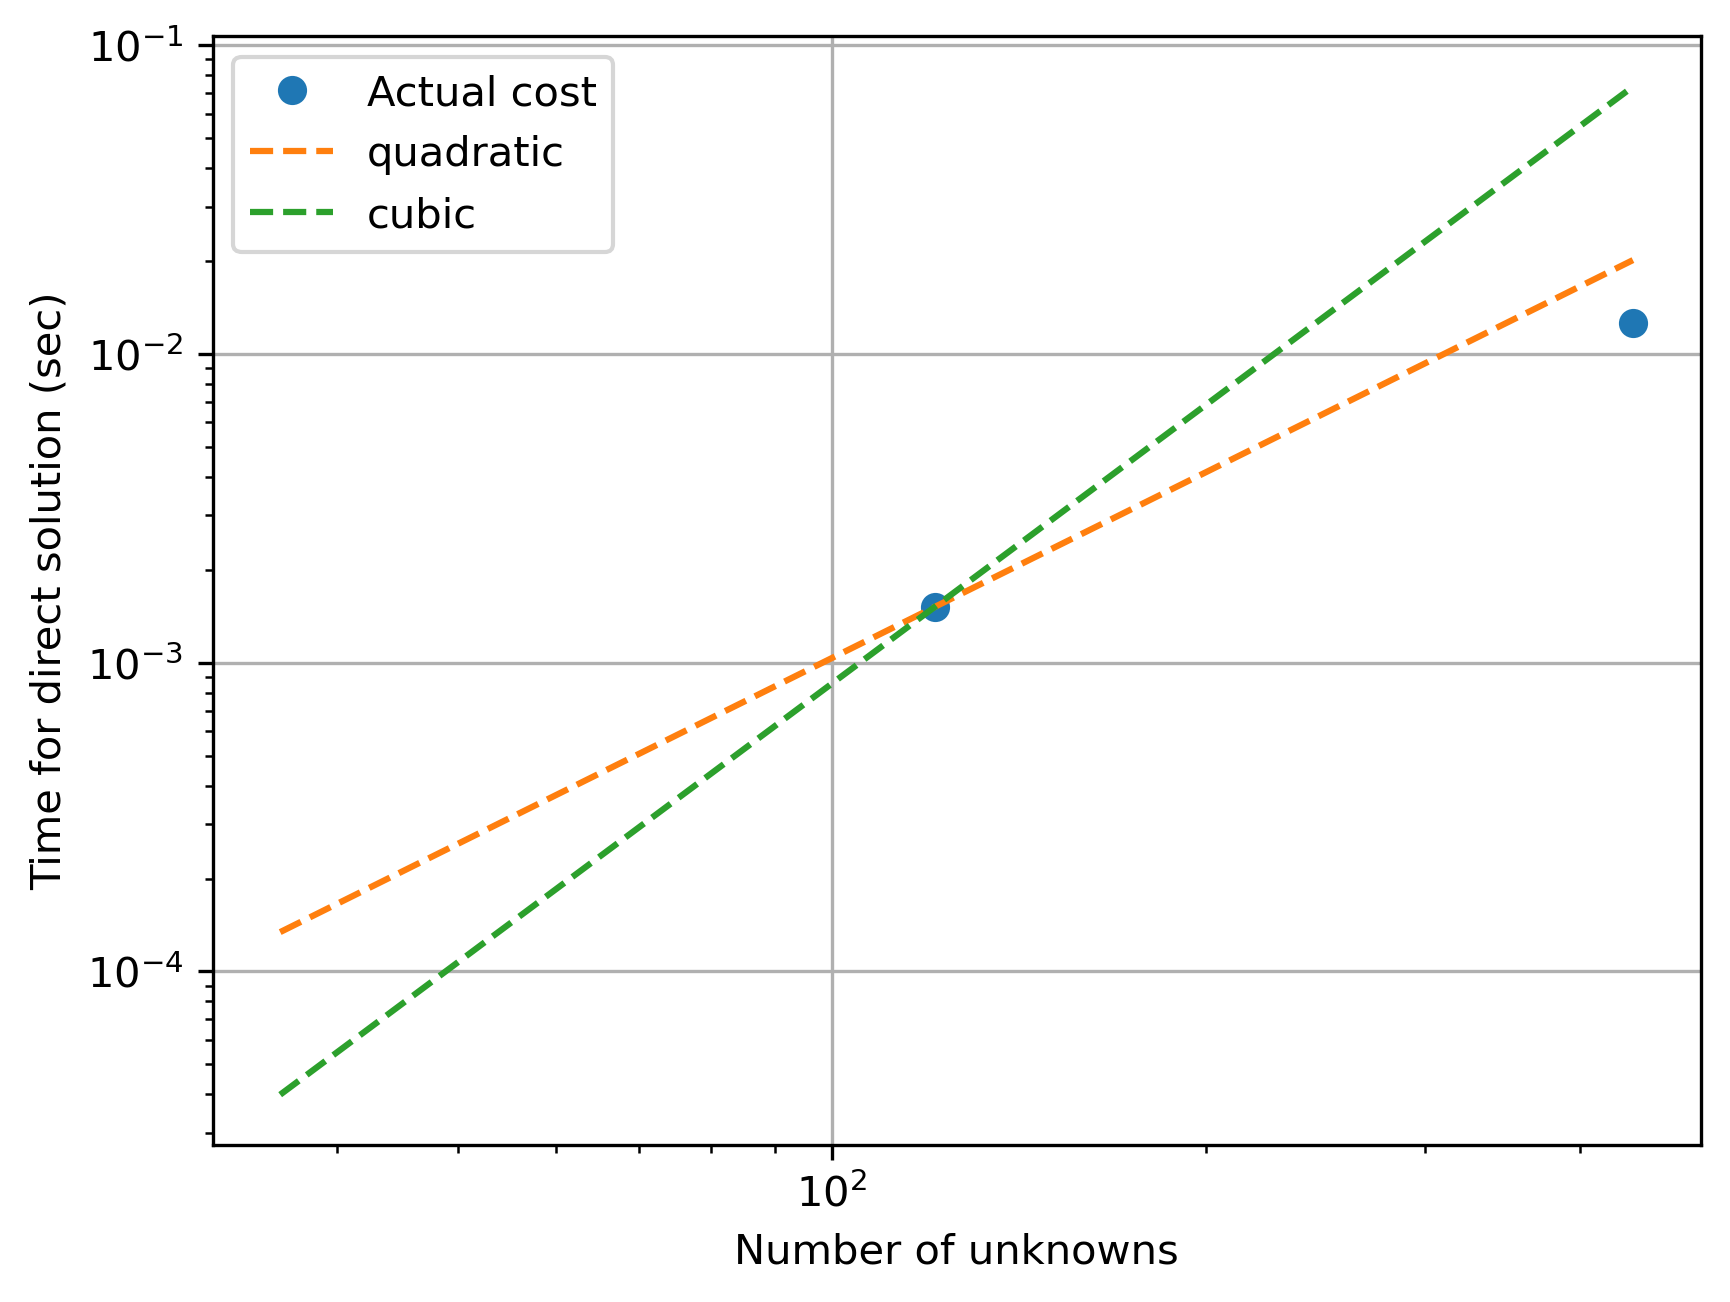

In [11]:
plt.loglog(num_pts, times, 'o', label='Actual cost')

plt.xlabel('Number of unknowns'); 
plt.ylabel('Time for direct solution (sec)')

x = num_pts[:]
n2 = x**2 * (times[1] / x[1]**2) 
n3 = x**3 * (times[1] / x[1]**3)
plt.loglog(x, n2, '--', label='quadratic')
plt.loglog(x, n3, '--', label='cubic')

plt.legend()
plt.grid(True)
plt.show()

\begin{equation}
A = \begin{bmatrix}
a_{0,0} & a_{0,1} & \cdots & a_{0,n-1} \\
a_{1,0} & a_{1,1} & \cdots & a_{1,n-1} \\
\vdots & \vdots & \ddots & \vdots \\
a_{n-1,0} & a_{n-1,1} & \cdots & a_{n-1,n-1} \end{bmatrix}
\quad \mathbf{x} = \begin{bmatrix} x_0 \\ x_1 \\ \vdots \\ x_{n-1} \end{bmatrix}
\quad \mathbf{b} = \begin{bmatrix} b_0 \\ b_1 \\ \vdots \\ b_{n-1} \end{bmatrix}
\end{equation}

\begin{equation}
x_i^{(k+1)} = \frac{1}{a_{ii}} \left( b_i - \sum_{j \neq i} a_{ij} x_j^{(k)} \right) , \quad i = 0,1,\ldots, n-1
\end{equation}

In [12]:
def heat_equation_jacobi(h):
    '''Solves heat equation using Jacobi iteration'''
    t0 = time.time()

    length_x = 1.0
    length_y = 1.0
    x_vals = np.arange(0, length_x + 0.001, h)
    y_vals = np.arange(0, length_y + 0.001, h)

    num_pts = len(x_vals)*len(y_vals)

    u = 100 * np.ones(num_pts)

    u_left = 100
    u_right = 100
    u_bottom = 100
    u_top = 0

    epsilon = 1.0

    num_iter = 0
    while epsilon > 1e-2:
        u_old = np.copy(u)
        epsilon = 0.0

        for j, y in enumerate(y_vals):
            for i, x in enumerate(x_vals):
                
                kij = j*len(x_vals) + i
                kim1j = j*len(x_vals) + i - 1
                kip1j = j*len(x_vals) + i + 1
                kijm1 = (j-1)*len(x_vals) + i
                kijp1 = (j+1)*len(x_vals) + i
                if i == 0:
                    # this is the left boundary
                    u[kij] = u_left
                elif i == len(x_vals) - 1:
                    # right boundary
                    u[kij] = u_right
                elif j == 0:
                    # bottom boundary
                    u[kij] = u_bottom
                elif j == len(y_vals) - 1:
                    # top boundary
                    u[kij] = u_top
                else:
                    
                    u[kij] = (
                        u_old[kip1j] + u_old[kim1j] + 
                        u_old[kijm1] + u_old[kijp1]
                        ) / 4.0
        epsilon = np.max(np.abs(u - u_old))
        num_iter += 1

    u_square = np.reshape(u, (len(y_vals), len(x_vals)))
    
    solution = {'num_points': num_pts,
                'time': time.time() - t0,
                'num_iter': num_iter,
                'u': u_square,
                'x': x_vals,
                'y': y_vals
                }

    return solution

In [13]:
step_sizes = [0.2, 0.1, 0.05]

num_pts_jac = np.zeros(len(step_sizes))
times_jac = np.zeros_like(num_pts_jac)
num_iter_jac = np.zeros_like(num_pts_jac)
for idx, step_size in enumerate(step_sizes):
    sol = heat_equation_jacobi(step_size)
    num_pts_jac[idx] = sol['num_points']
    times_jac[idx] = sol['time']
    num_iter_jac[idx] = sol['num_iter']
    x_vals = sol['x']
    y_vals = sol['y']
    u = sol['u']
    print(f"Number of iterations: {sol['num_iter']}")

Number of iterations: 33
Number of iterations: 107
Number of iterations: 317


\begin{equation}
A = \begin{bmatrix}
a_{0,0} & a_{0,1} & \cdots & a_{0,n-1} \\
a_{1,0} & a_{1,1} & \cdots & a_{1,n-1} \\
\vdots & \vdots & \ddots & \vdots \\
a_{n-1,0} & a_{n-1,1} & \cdots & a_{n-1,n-1} \end{bmatrix}
\quad \mathbf{x} = \begin{bmatrix} x_0 \\ x_1 \\ \vdots \\ x_{n-1} \end{bmatrix}
\quad \mathbf{b} = \begin{bmatrix} b_0 \\ b_1 \\ \vdots \\ b_{n-1} \end{bmatrix}
\end{equation}

\begin{equation}
x_i^{(k+1)} = \frac{1}{a_{ii}} \left( b_i - \sum_{j=1}^{i-1} a_{ij} x_j^{(k+1)} - \sum_{j =i+1}^n a_{ij} x_j^{(k)} \right) , \quad i = 0,1,\ldots, n-1
\end{equation}

In [14]:
def heat_equation_gauss_seidel(h):
    '''Solves heat equation using the Gauss-Seidel method'''
    t0 = time.time()

    length_x = 1.0
    length_y = 1.0
    x_vals = np.arange(0, length_x + 0.001, h)
    y_vals = np.arange(0, length_y + 0.001, h)

    num_pts = len(x_vals)*len(y_vals)

    u = 100 * np.ones(num_pts)

    u_left = 100
    u_right = 100
    u_bottom = 100
    u_top = 0

    epsilon = 1.0

    num_iter = 0
    while epsilon > 1e-2:
        u_old = np.copy(u)
        epsilon = 0.0

        for j, y in enumerate(y_vals):
            for i, x in enumerate(x_vals):
                
                kij = j*len(x_vals) + i
                kim1j = j*len(x_vals) + i - 1
                kip1j = j*len(x_vals) + i + 1
                kijm1 = (j-1)*len(x_vals) + i
                kijp1 = (j+1)*len(x_vals) + i
                if i == 0:
                    # this is the left boundary
                    u[kij] = u_left
                elif i == len(x_vals) - 1:
                    # right boundary
                    u[kij] = u_right
                elif j == 0:
                    # bottom boundary
                    u[kij] = u_bottom
                elif j == len(y_vals) - 1:
                    # top boundary
                    u[kij] = u_top
                else:
                    
                    u[kij] = (
                        u[kip1j] + u[kim1j] + 
                        u[kijm1] + u[kijp1]
                        ) / 4.0
        epsilon = np.max(np.abs(u - u_old))
        num_iter += 1

    u_square = np.reshape(u, (len(y_vals), len(x_vals)))
    
    solution = {'num_points': num_pts,
                'time': time.time() - t0,
                'num_iter': num_iter,
                'u': u_square,
                'x': x_vals,
                'y': y_vals
                }

    return solution

In [15]:
step_sizes = [0.2, 0.1, 0.05]

num_pts_gs = np.zeros(len(step_sizes))
times_gs = np.zeros_like(num_pts_gs)
num_iter_gs = np.zeros_like(num_pts_gs)
for idx, step_size in enumerate(step_sizes):
    sol = heat_equation_gauss_seidel(step_size)
    num_pts_gs[idx] = sol['num_points']
    times_gs[idx] = sol['time']
    num_iter_gs[idx] = sol['num_iter']
    x_vals = sol['x']
    y_vals = sol['y']
    u = sol['u']
    print(f"Number of iterations: {sol['num_iter']}")

Number of iterations: 21
Number of iterations: 64
Number of iterations: 193


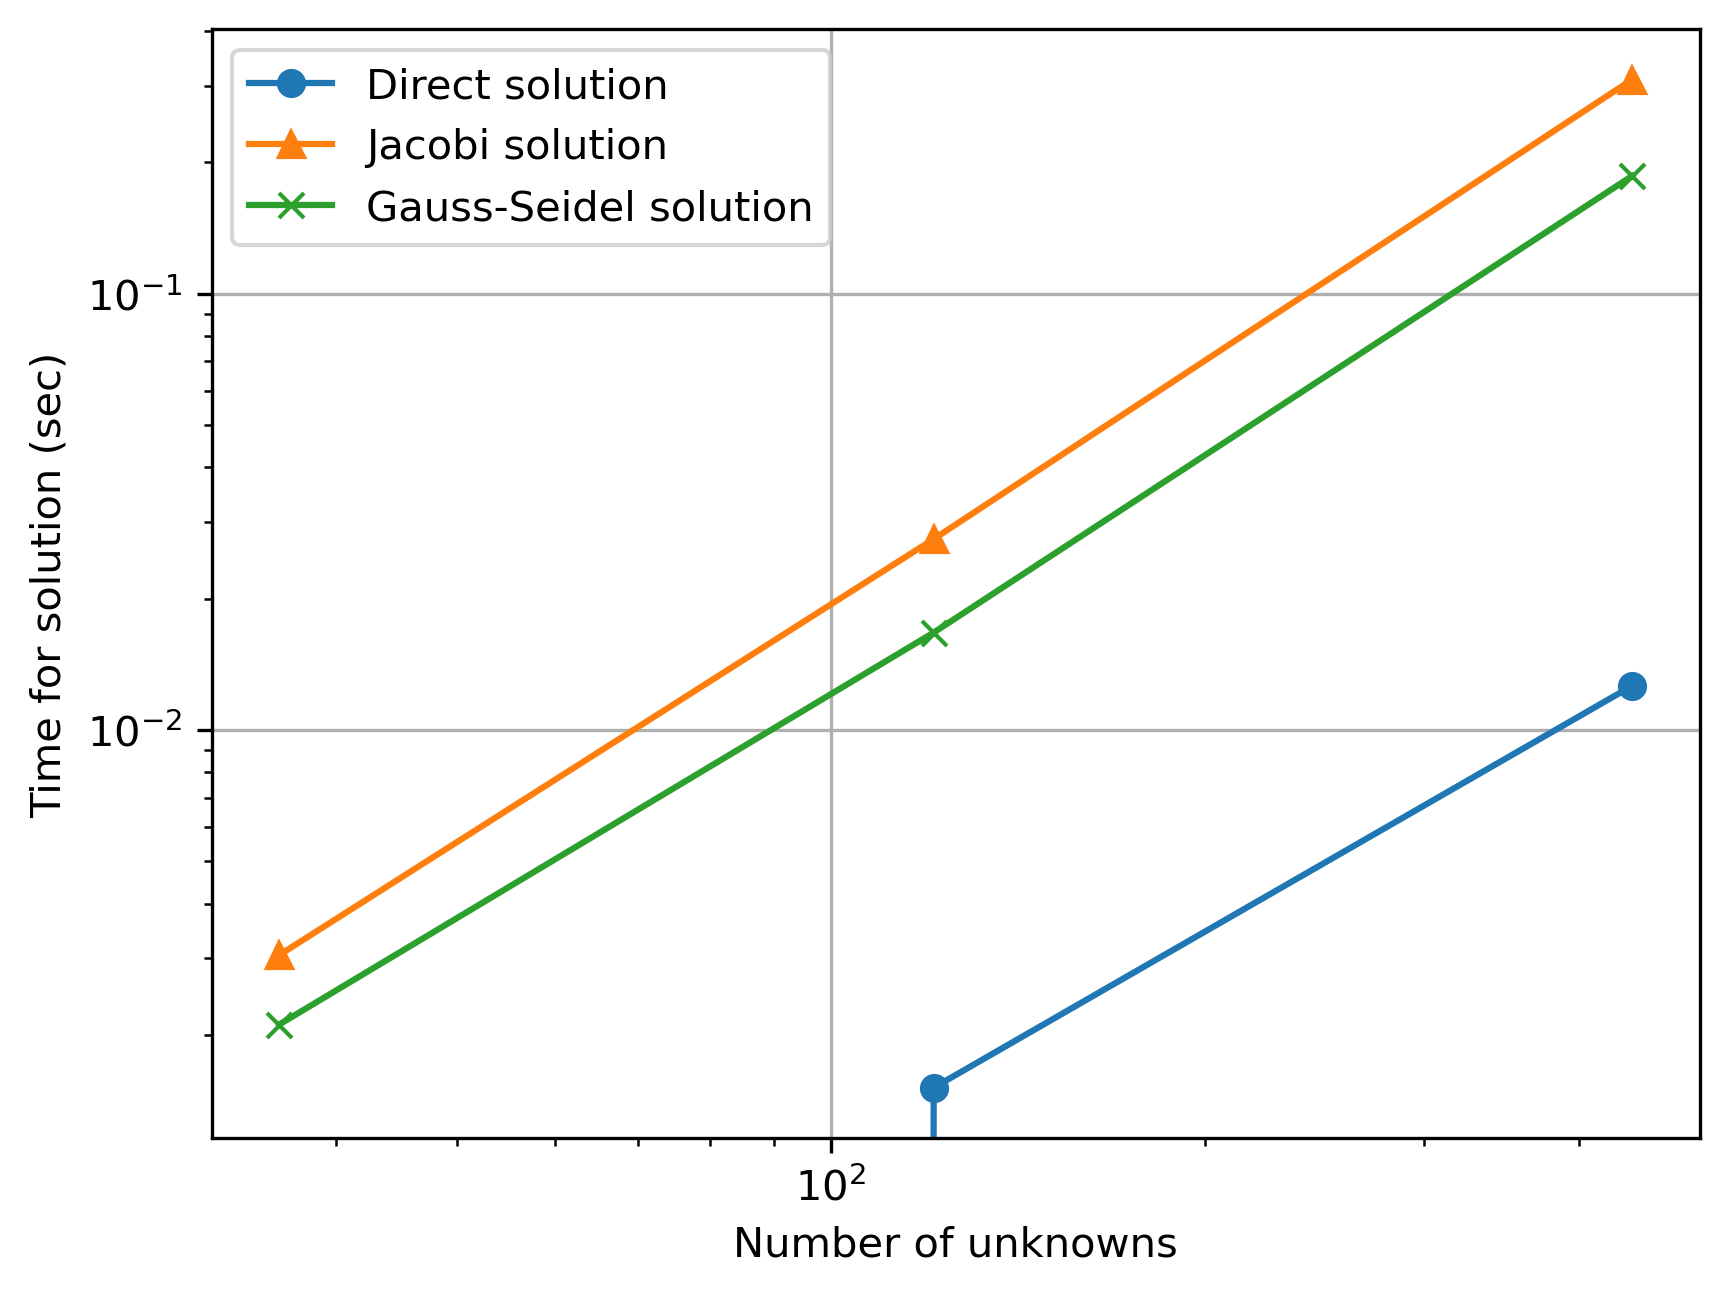

In [16]:
plt.loglog(num_pts, times, '-o', label='Direct solution')
plt.loglog(num_pts_jac, times_jac, '-^', label='Jacobi solution')
plt.loglog(num_pts_gs, times_gs, '-x', label='Gauss-Seidel solution')
plt.xlabel('Number of unknowns')
plt.ylabel('Time for solution (sec)')
plt.legend()
plt.grid()
plt.show()

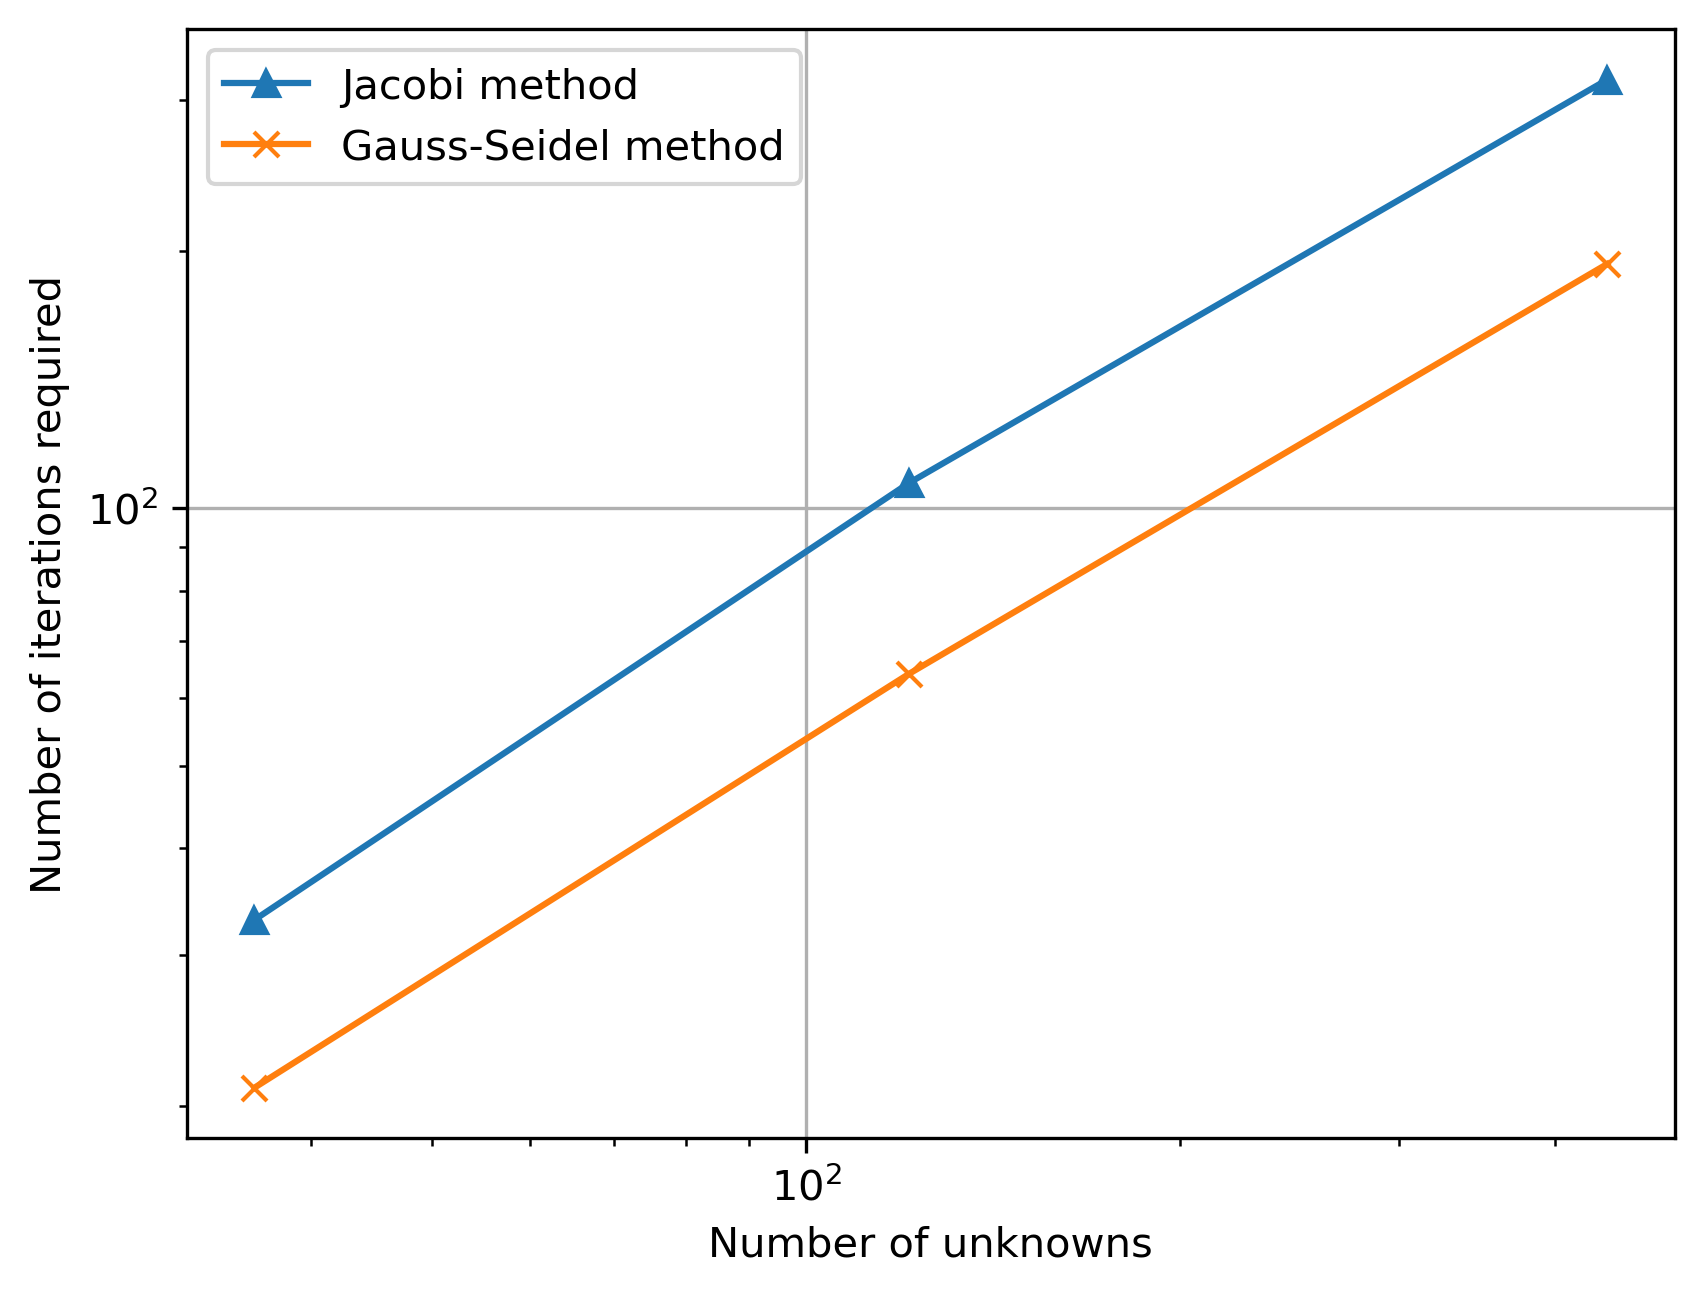

In [17]:
plt.loglog(num_pts_jac, num_iter_jac, '-^', label='Jacobi method')
plt.loglog(num_pts_gs, num_iter_gs, '-x', label='Gauss-Seidel method')
plt.xlabel('Number of unknowns')
plt.ylabel('Number of iterations required')
plt.legend()
plt.grid()
plt.show()